In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [ ]:
gamma = 2 * np.pi * 42.58e6
M0 = np.array([0,0,1])

T_1 = 1400e-3
T_2 = 25e-3

In [9]:
# Amplitudenmdoulation und Phasenmodulation

def B1x(t, A0, beta):
    B1_ampl = A0 / np.cosh(beta * (t-0))
    return B1_ampl

def delta_omega(t, mu, beta):
    phase_mod_rad = - mu * beta * np.tanh(beta * t)
    phase_mod = phase_mod_rad / (2 * np.pi)
    return phase_mod                                    # in Hz

# Bandbreite

def delta_f(mu, beta):
    bandbreite = mu * beta / np.pi
    return bandbreite

# Bloch-Gleichung

def bloch_rot(t,M,A0,mu,beta,T_1,T_2):
    B1_x = B1x(t, A0, beta)
    B1_z = 2 * np.pi * delta_omega(t, mu, beta) / gamma
    B1_vec = np.array([B1_x, 0, B1_z])
    dMdt = gamma * np.cross(M,B1_vec) + 1/T_1 * (M0 - np.array([0,0,M[2]])) - 1/T_2 * (np.array([M[0],M[1],0]))
    return dMdt

# Adiabatische Bedingung: << 1

def adiabatic(A0, mu, beta):
    epsilon = (np.sqrt(mu) * beta) / (gamma * A0)
    return epsilon

In [ ]:
# Puls Parameter

A0 = 12e-6
beta = 250
mu = 3.9

pulse_duration = 15e-3                      # Achtung! Das ist die halbe Pulsdauer
t_start = - pulse_duration
t_end = pulse_duration
times = np.linspace(t_start, t_end, 2000)

print("Bandbreite:", delta_f(mu, beta))
print("Adiabatischer Faktor:", adiabatic(A0, mu, beta))

Bandbreite: 310.35213902919594
Adiabatischer Faktor: 0.15378201270818165


In [27]:
# Berechnung Amplitude und Phase

time_values = times
amp_values = np.array([B1x(t, A0, beta) for t in times])
phase_values = np.array([delta_omega(t, mu, beta) for t in times])

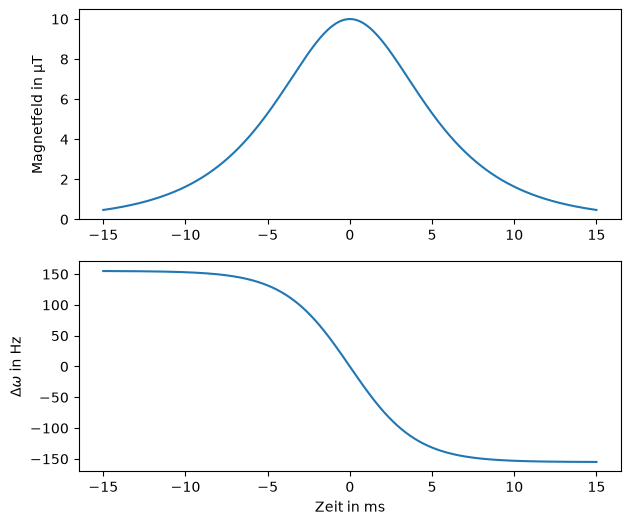

In [28]:
# Amplitude und Phase plotten

fig, ax = plt.subplots(2,1, figsize=(7,6))

ax[0].plot(time_values*1e3, amp_values*1e6)
ax[0].set_ylabel("Magnetfeld in µT")

ax[1].plot(time_values*1e3, phase_values)
ax[1].set_xlabel("Zeit in ms")
ax[1].set_ylabel(r"$\Delta \omega$ in Hz")

plt.show()

In [29]:
# Bloch-Gleichung lösen

solution = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta, T_1, T_2), t_eval = time_values)
Mx = solution.y[0]
My = solution.y[1]
Mz = solution.y[2]

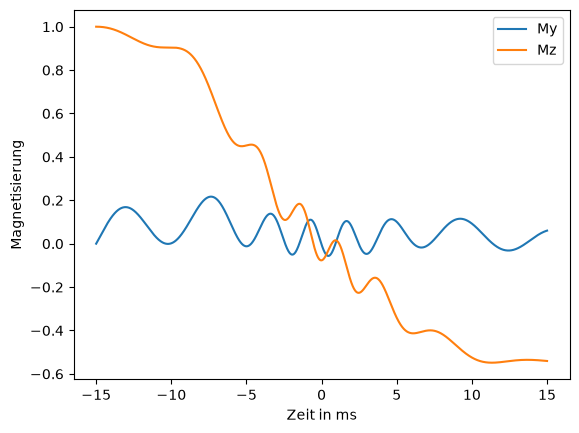

In [30]:
# Magnetisierung plotten

plt.figure()

#plt.plot(times * 1e3, Mx, label = "Mx")
plt.plot(times * 1e3, My, label = "My")
plt.plot(times * 1e3, Mz, label = "Mz")

plt.xlabel("Zeit in ms")
plt.ylabel("Magnetisierung")
#plt.title()
plt.legend()
plt.show()

In [31]:
print("Adiabatischer Faktor:", adiabatic(A0, mu, beta))

Adiabatischer Faktor: 0.18453841524981796


In [32]:
last_times = int(0.05 * len(times))
inversionsgrad = np.mean(Mz[-last_times:])
print("Longitudinale Komponente am Pulsende:", np.round(inversionsgrad,3))

Longitudinale Komponente am Pulsende: -0.537


Text(0, 0.5, 'longitudinale Endmagnetisierung')

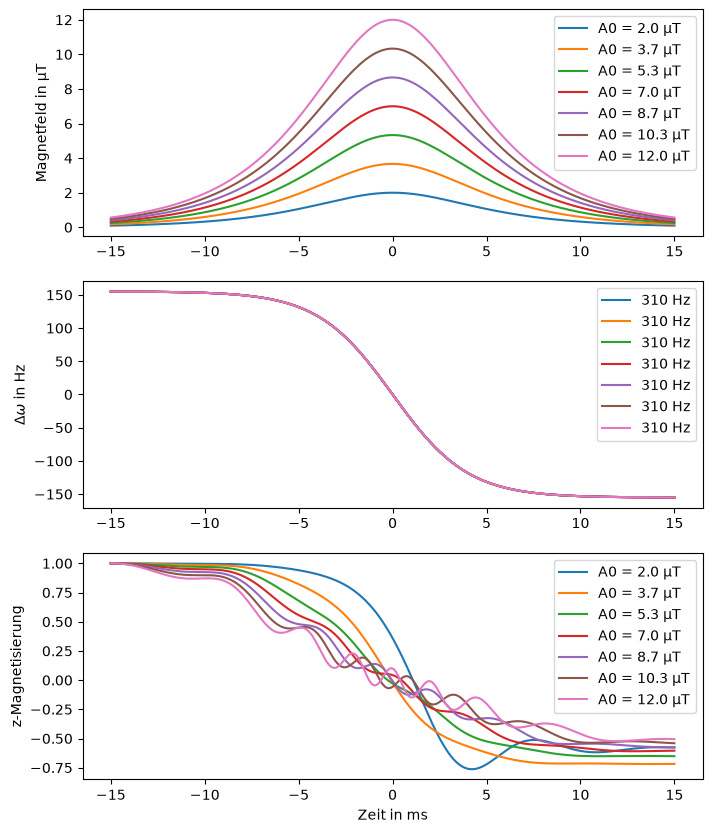

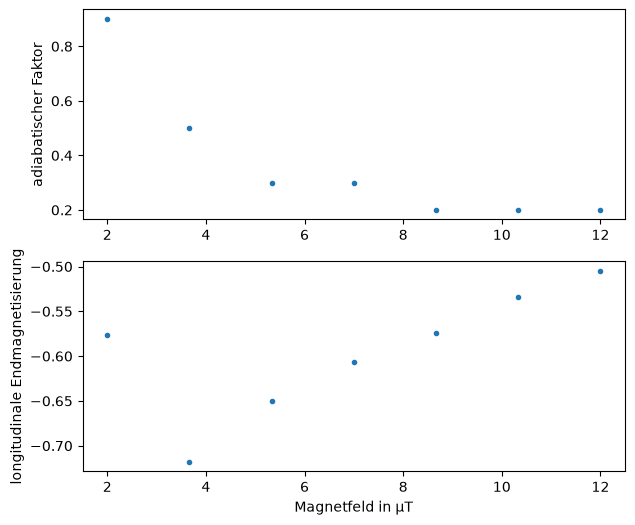

In [33]:
# Variation A0

A0_range = np.linspace(2e-6, 12e-6, 7)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(3,1, figsize=(8,10))

for A0_value in A0_range:
    
    amp_values = np.array([B1x(t, A0_value, beta) for t in times])
    phase_values = np.array([delta_omega(t, mu, beta) for t in times])

    bandbreite_values = delta_f(mu, beta)

    epsilon = np.round(adiabatic(A0_value, mu, beta),1)
    epsilons.append(epsilon)

    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, mu, beta, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)
    
    ax1[0].plot(times*1e3, amp_values*1e6, label = f"A0 = {A0_value*1e6:.1f} µT")
    ax1[0].legend()
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, phase_values, label = f"{bandbreite_values:.0f} Hz")
    ax1[1].legend()
    ax1[1].set_ylabel(r"$\Delta \omega$ in Hz")

    ax1[2].plot(times*1e3, Mzs, label = f"A0 = {A0_value*1e6:.1f} µT")
    ax1[2].legend()
    ax1[2].set_xlabel("Zeit in ms")
    ax1[2].set_ylabel("z-Magnetisierung")
    

fig2, ax2 = plt.subplots(2,1, figsize=(7,6))

ax2[0].plot(A0_range*1e6, epsilons, ".")
ax2[0].set_ylabel("adiabatischer Faktor")

ax2[1].plot(A0_range*1e6,inversionsgrade, ".")
ax2[1].set_xlabel("Magnetfeld in µT")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")

Text(0, 0.5, 'longitudinale Endmagnetisierung')

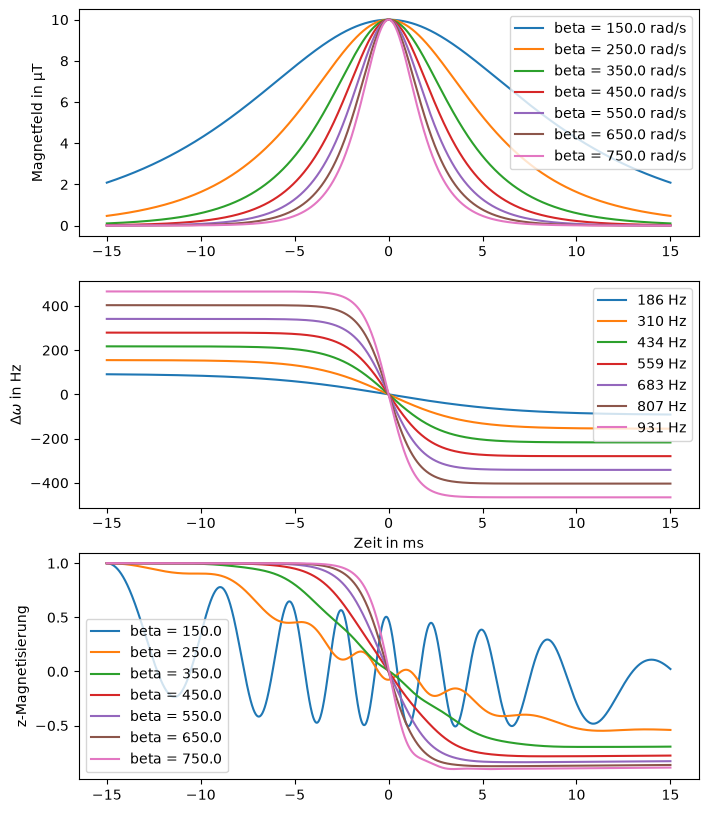

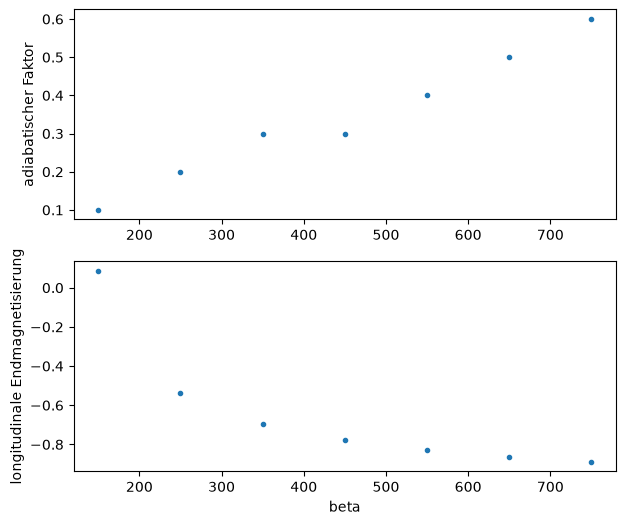

In [35]:
# Variation beta

beta_range = np.linspace(150, 750, 7)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(3,1, figsize=(8,10))

for beta_value in beta_range:
    
    amp_values = np.array([B1x(t, A0, beta_value) for t in times])
    phase_values = np.array([delta_omega(t, mu, beta_value) for t in times])

    bandbreite_values = delta_f(mu, beta_value)

    epsilon = np.round(adiabatic(A0, mu, beta_value),1)
    epsilons.append(epsilon)

    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta_value, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)
    
    ax1[0].plot(times*1e3, amp_values*1e6, label = f"beta = {beta_value:.1f} rad/s")
    ax1[0].legend()
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, phase_values, label = f"{bandbreite_values:.0f} Hz")
    ax1[1].legend()
    ax1[1].set_ylabel(r"$\Delta \omega$ in Hz")
    
    ax1[2].plot(times*1e3, Mzs, label = f"beta = {beta_value:.1f}")
    ax1[2].legend()
    ax1[1].set_xlabel("Zeit in ms")
    ax1[2].set_ylabel("z-Magnetisierung")


fig2, ax2 = plt.subplots(2,1, figsize=(7,6))

ax2[0].plot(beta_range, epsilons, ".")
ax2[0].set_ylabel("adiabatischer Faktor")

ax2[1].plot(beta_range,inversionsgrade, ".")
ax2[1].set_xlabel("beta")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")

Text(0, 0.5, 'longitudinale Endmagnetisierung')

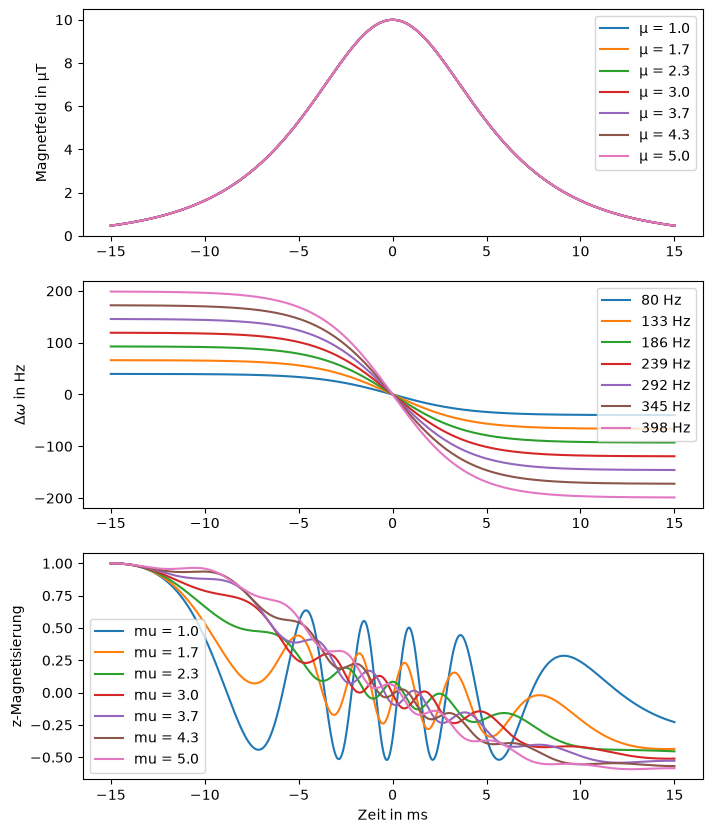

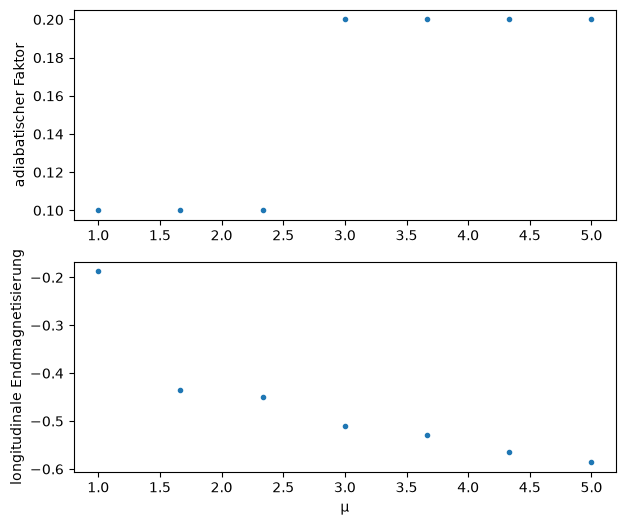

In [37]:
# Variation mu

mu_range = np.linspace(1, 5, 7)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(3,1, figsize=(8,10))

for mu_value in mu_range:
    
    amp_values = np.array([B1x(t, A0, beta) for t in times])
    phase_values = np.array([delta_omega(t, mu_value, beta) for t in times])
    
    bandbreite_values = delta_f(mu_value, beta)

    epsilon = np.round(adiabatic(A0, mu_value, beta),1)
    epsilons.append(epsilon)

    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu_value, beta, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)
    
    ax1[0].plot(times*1e3, amp_values*1e6, label = f"µ = {mu_value:.1f}")
    ax1[0].legend()
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, phase_values, label = f"{bandbreite_values:.0f} Hz")
    ax1[1].legend()
    ax1[1].set_ylabel(r"$\Delta \omega$ in Hz")

    ax1[2].plot(times*1e3, Mzs, label = f"mu = {mu_value:.1f}")
    ax1[2].legend()
    ax1[2].set_xlabel("Zeit in ms")
    ax1[2].set_ylabel("z-Magnetisierung")


fig2, ax2 = plt.subplots(2,1, figsize=(7,6))

ax2[0].plot(mu_range, epsilons, ".")
ax2[0].set_ylabel("adiabatischer Faktor")

ax2[1].plot(mu_range,inversionsgrade, ".")
ax2[1].set_xlabel("µ")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")

Text(0, 0.5, 'longitudinale Endmagnetisierung')

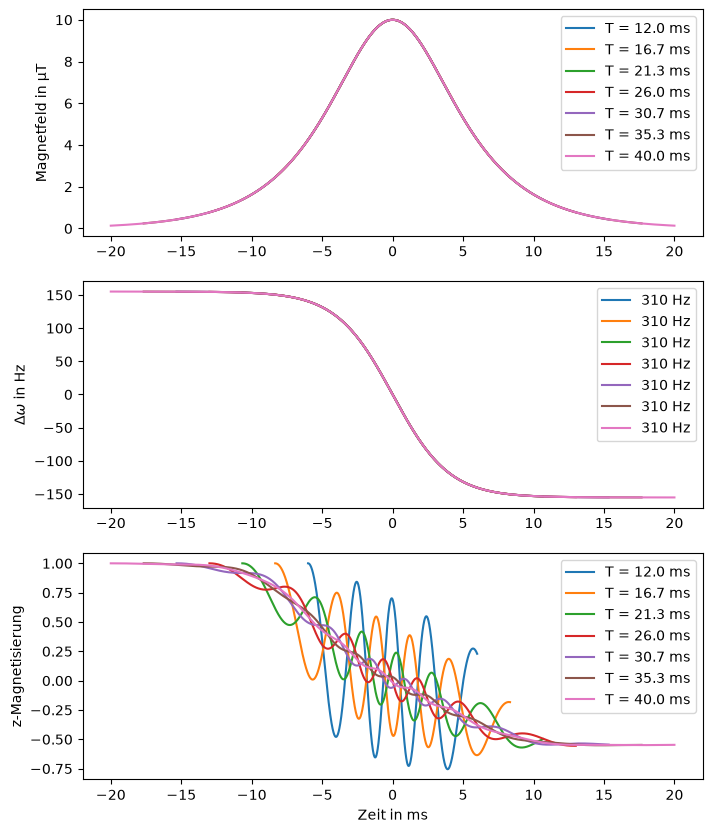

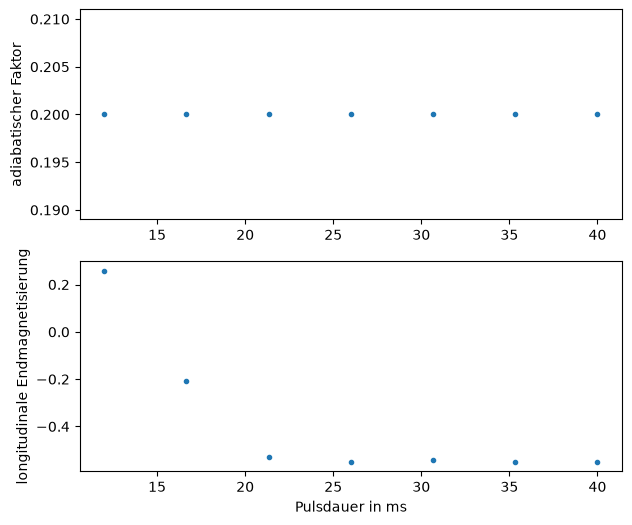

In [39]:
# Variation T

T_range = np.linspace(6e-3, 20e-3, 7)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(3,1, figsize=(8,10))

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    amp_values = np.array([B1x(t, A0, beta) for t in times])
    phase_values = np.array([delta_omega(t, mu, beta) for t in times])

    bandbreite_values = delta_f(mu, beta)

    epsilon = np.round(adiabatic(A0, mu, beta),1)
    epsilons.append(epsilon)

    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta, T_1, T_2), t_eval = times)
    Mzs = solutions.y[2]

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"T = {2*T_value*1e3:.1f} ms")
    ax1[0].legend()
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, phase_values, label = f"{bandbreite_values:.0f} Hz")
    ax1[1].legend()
    ax1[1].set_ylabel(r"$\Delta \omega$ in Hz")

    ax1[2].plot(times*1e3, Mzs, label = f"T = {2*T_value*1e3:.1f} ms")
    ax1[2].legend()
    ax1[2].set_xlabel("Zeit in ms")
    ax1[2].set_ylabel("z-Magnetisierung")


fig2, ax2 = plt.subplots(2,1, figsize=(7,6))

ax2[0].plot(2*T_range*1e3, epsilons, ".")
ax2[0].set_ylabel("adiabatischer Faktor")

ax2[1].plot(2*T_range*1e3,inversionsgrade, ".")
ax2[1].set_xlabel("Pulsdauer in ms")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")

In [56]:
# Variation A0 und T

T_range = np.linspace(0.1e-3, 15e-3, 30)
A0_range = np.linspace(2e-6, 12e-6, 10)

epsilons = []
inversionsgrade = []
winkels = []

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    epsilons2 = []
    inversionsgrade2 = []
    winkels2 = []

    for A0_value in A0_range:

        epsilon = np.round(adiabatic(A0_value, mu, beta),2)
        epsilons2.append(epsilon)

        solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, mu, beta, T_1, T_2), t_eval = times)
        Mzs = solutions.y[2]

        last_times = int(0.05 * len(times))
        inversionsgrad = np.mean(Mzs[-last_times:])
        # inversionsgrad = Mzs[-1]
        inversionsgrade2.append(inversionsgrad)

        Mz_end = np.mean(Mzs[-last_times:])
        Mz_end = np.clip(Mz_end, -1, 1)
        winkel = np.degrees(np.arccos(Mz_end))
        winkels2.append(winkel)

    epsilons.append(epsilons2)
    inversionsgrade.append(inversionsgrade2)  
    winkels.append(winkels2)

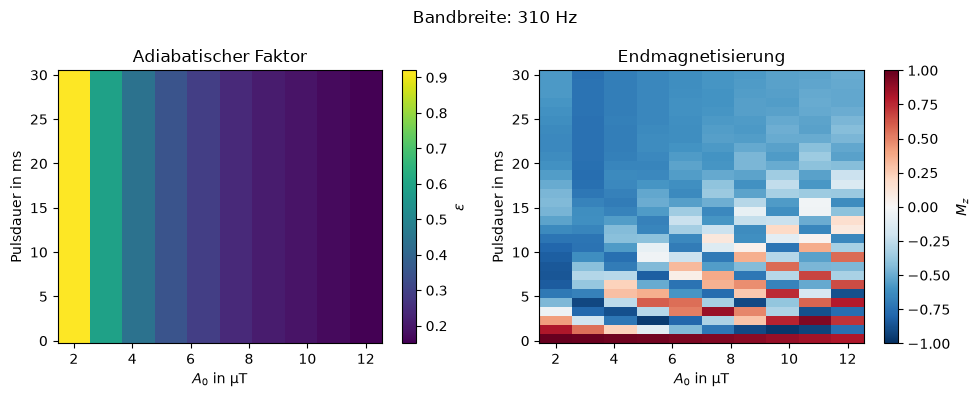

In [57]:
fig, ax = plt.subplots(1,2, figsize=(10, 4))

im1 = ax[0].pcolormesh(A0_range*1e6, 2*T_range*1e3, epsilons, shading="auto")

ax[0].set_xlabel(r"$A_0$ in µT")
ax[0].set_ylabel("Pulsdauer in ms")
ax[0].set_title("Adiabatischer Faktor")

fig.colorbar(im1, ax=ax[0], label=r"$\epsilon$")

im2 = ax[1].pcolormesh(A0_range*1e6, 2*T_range*1e3, inversionsgrade, shading="auto",
                        cmap="RdBu_r", vmin=-1, vmax=1)

ax[1].set_xlabel(r"$A_0$ in µT")
ax[1].set_ylabel("Pulsdauer in ms")
ax[1].set_title("Endmagnetisierung")

fig.colorbar(im2, ax=ax[1], label=r"$M_z$")

fig.suptitle(
    f"Bandbreite: {delta_f(mu,beta):.0f} Hz"
)
fig.tight_layout()
plt.show()

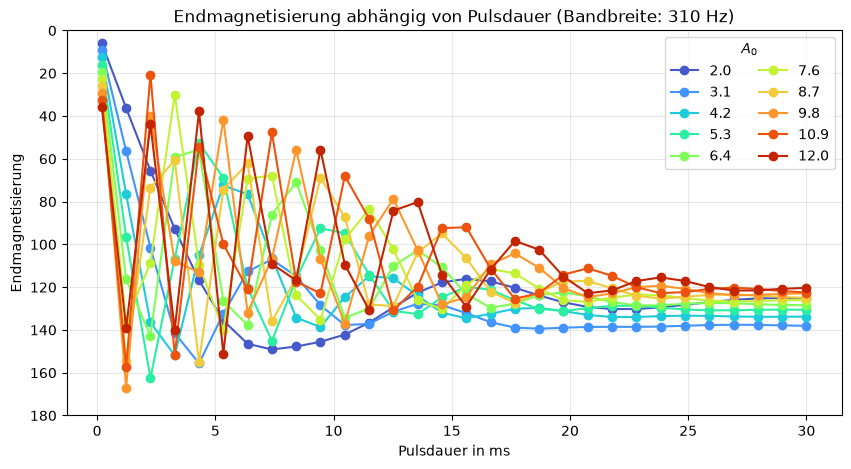

In [58]:
fig, ax = plt.subplots(figsize=(10,5))

# colors = ["blue", "red", "green", "orange", "purple", "black", "cyan", "magenta", "brown", "gray"]
colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(A0_range)))

for i, A0_value in enumerate(A0_range):
    ax.plot(2*T_range*1e3, np.array(winkels)[:,i], "-o", color=colors[i], label=f"{A0_value*1e6:.1f}")

ax.set_xlabel("Pulsdauer in ms")
ax.set_ylabel("Endmagnetisierung")
ax.set_ylim(180, 0)
ax.set_title(f"Endmagnetisierung abhängig von Pulsdauer (Bandbreite: {delta_f(mu,beta):.0f} Hz)")
ax.grid(True, alpha=0.3)
ax.legend(title=r"$A_0$", ncol=2)
plt.show()